# Visualize Mirrored PCB Dataset

`data/processed/pcb_mirror_rtdetr` içindeki COCO anotasyonlarını, mirror padding'i ve valid mask'leri inceler. **Verileri değiştirmez.**

Her örnekte: orijinal görüntü, mirror-padded görüntü, COCO bounding box'ları ve valid mask gösterilir. Notebook'u `RT-DETR/notebooks/visualize_mirrored_dataset.ipynb` konumuna koyabilirsiniz.


In [5]:
from pathlib import Path
import json
import random
from collections import defaultdict

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Notebook notebooks/ altında veya proje kökünde açılırsa çalışır.
ROOT = Path.cwd().resolve()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

RAW = ROOT / "data/raw/pcb_clean_split"
PROCESSED = ROOT / "data/processed/pcb_mirror_rtdetr_1024_v2"
SPLIT = "train"  # "val" veya "test" de olabilir
N_SAMPLES = 5
SEED = 42

assert RAW.is_dir(), f"Orijinal veri bulunamadı: {RAW}"
assert PROCESSED.is_dir(), f"İşlenmiş veri bulunamadı: {PROCESSED}"
print("Project root:", ROOT)


Project root: /Users/iremkeser/rtdetr_reproduction/RT-DETR


In [6]:
ann_file = PROCESSED / "annotations" / f"instances_{SPLIT}.json"
with ann_file.open(encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
by_image = defaultdict(list)
for a in coco["annotations"]:
    by_image[a["image_id"]].append(a)
category_names = {c["id"]: c["name"] for c in coco["categories"]}

print(f"{SPLIT}: {len(images)} görüntü, {len(coco['annotations'])} kutu")
print("Sınıflar:", category_names)
assert images, "Görüntü bulunamadı"


train: 6399 görüntü, 12990 kutu
Sınıflar: {1: 'mouse_bite', 2: 'spur', 3: 'missing_hole', 4: 'short', 5: 'open_circuit', 6: 'spurious_copper'}


## Rastgele örnekleri görselleştir

**Valid mask:** beyaz (255) gerçek görüntü alanı, siyah (0) mirror padding alanı. Yeşil dikdörtgen gerçek görüntünün sınırını gösterir. Kırmızı kutular COCO anotasyonlarıdır.


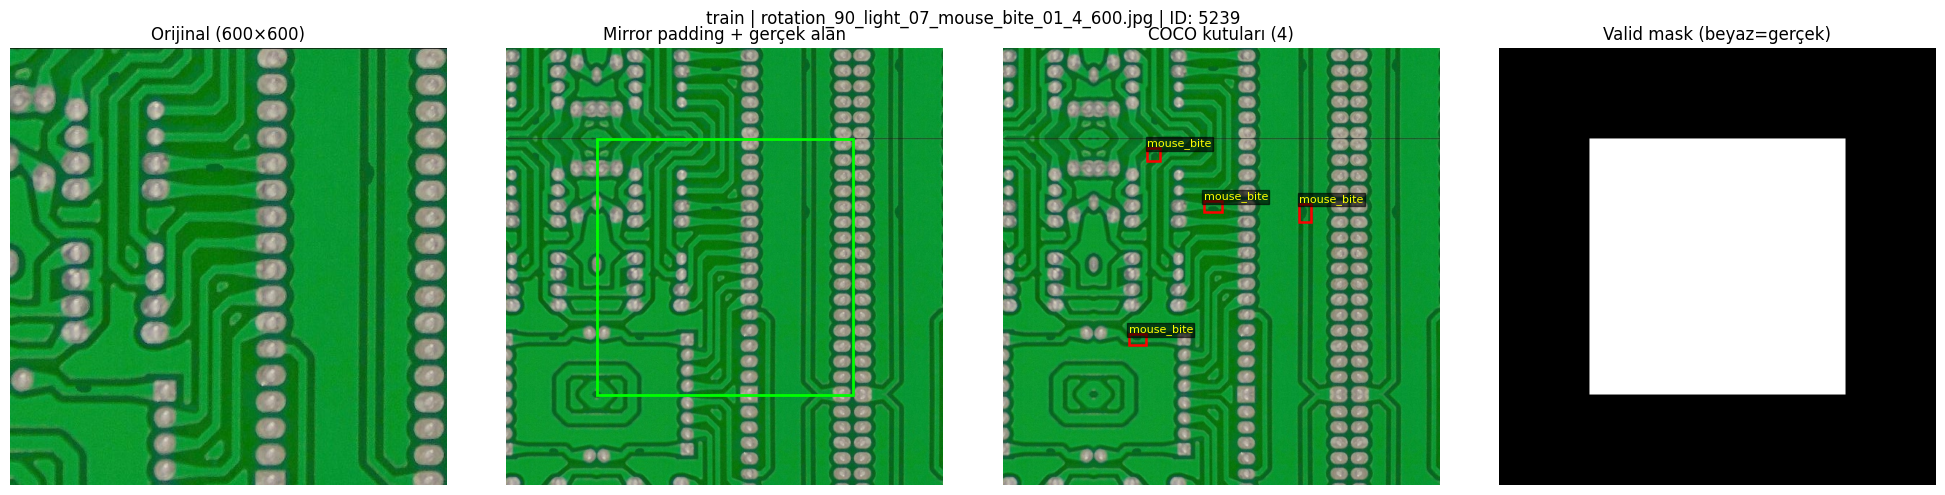

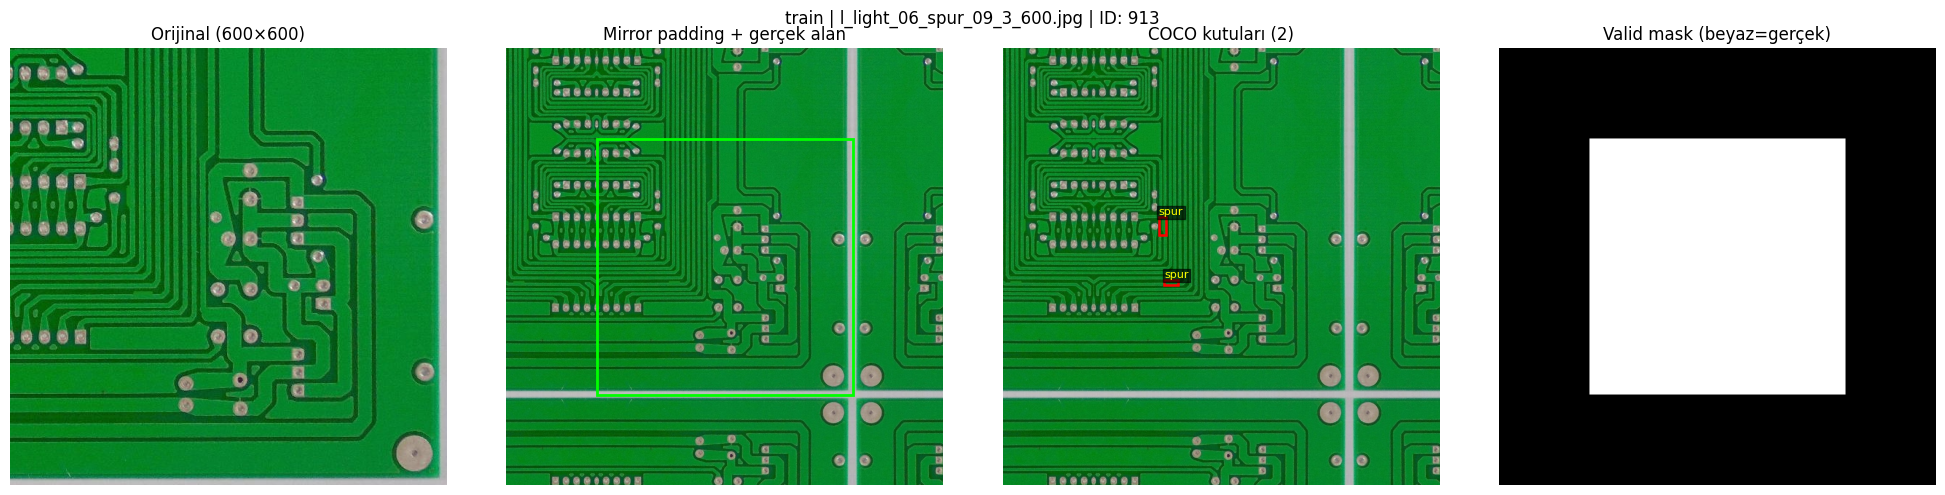

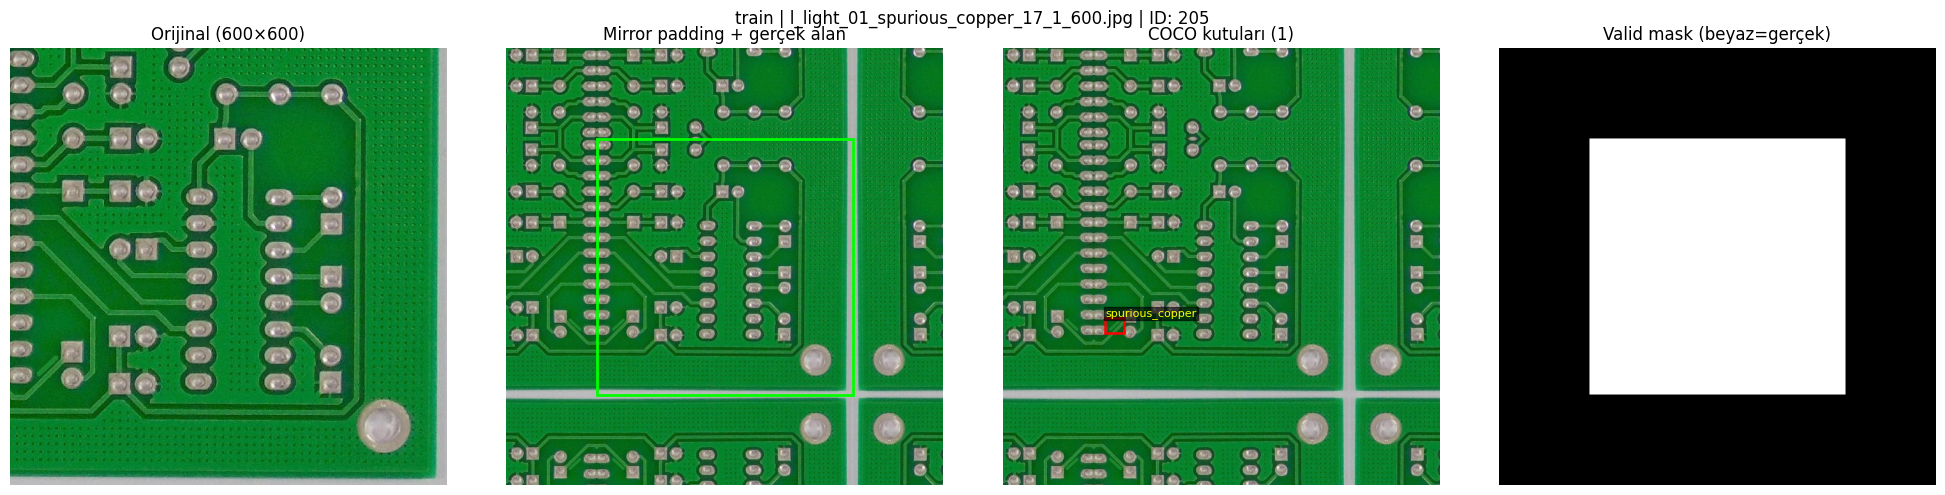

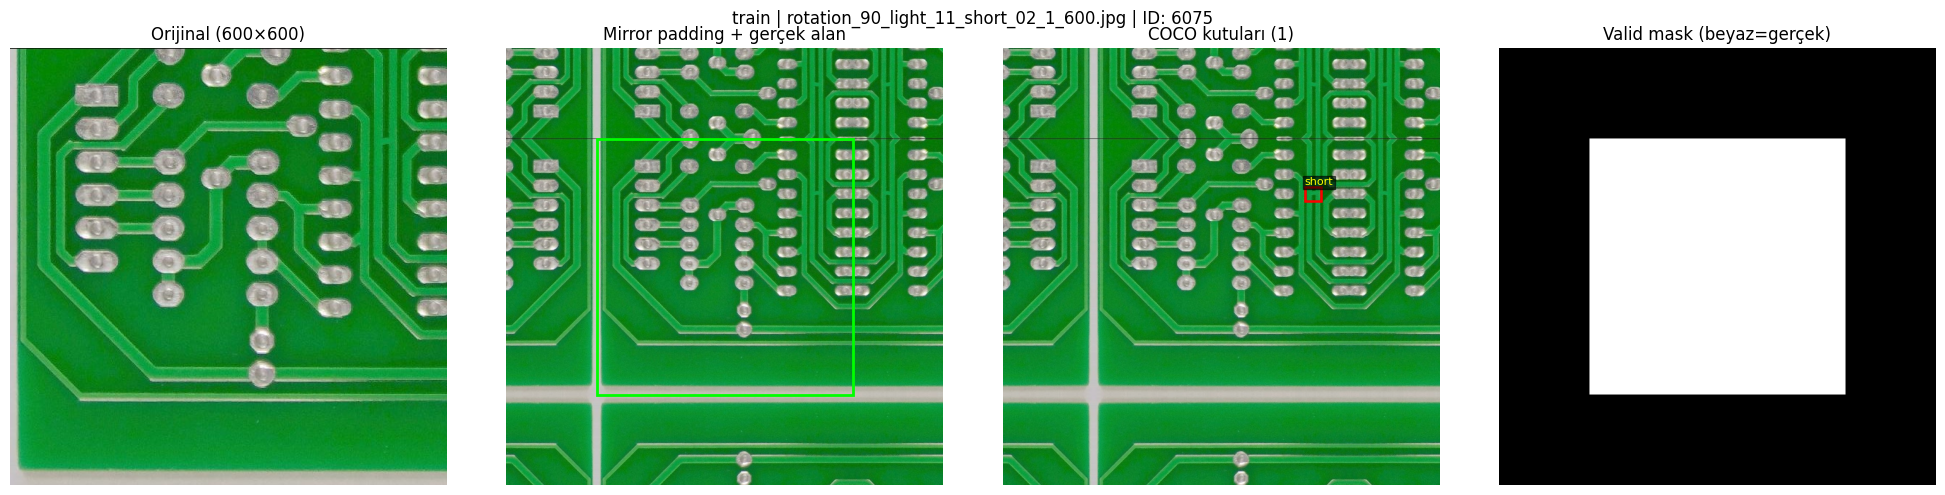

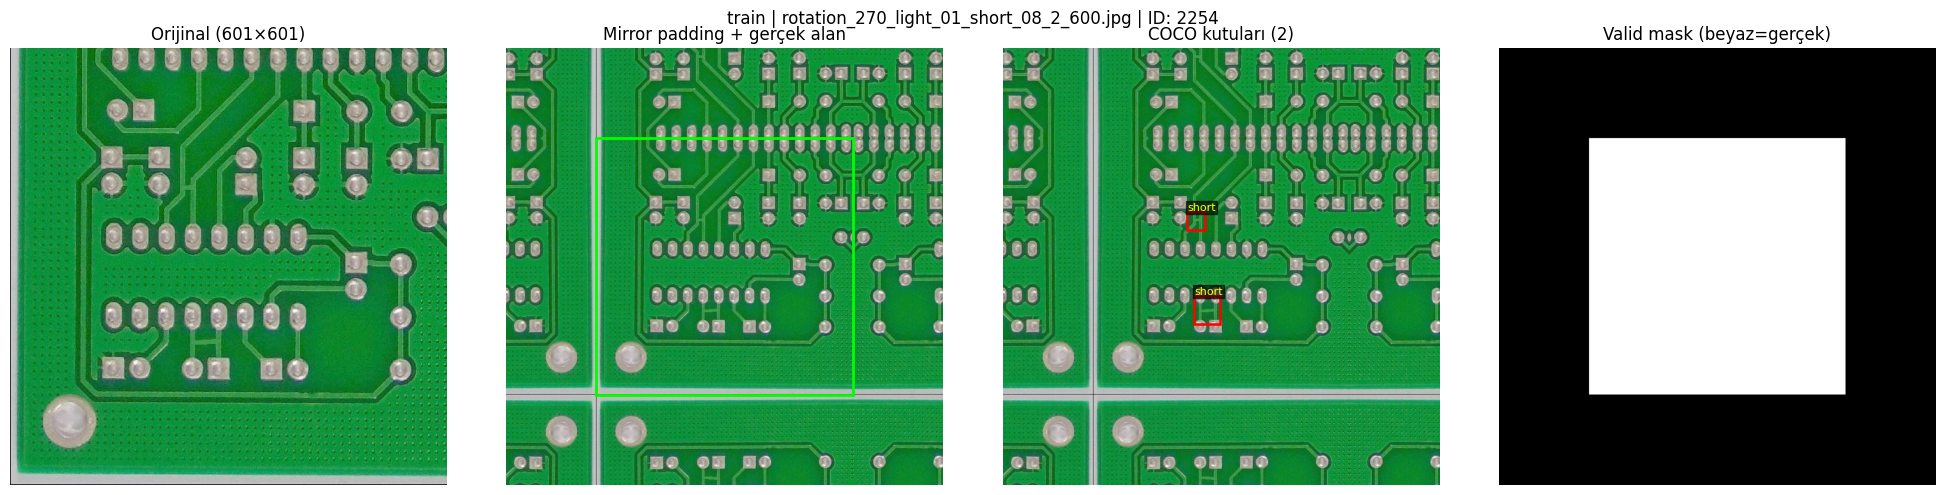

In [7]:
def read_rgb(path):
    im = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(path)
    return cv2.cvtColor(im, cv2.COLOR_BGR2RGB)


def original_path_from_processed(file_name, split):
    # Örnek: train/images/subdir/a.png -> train/images/subdir/a.{jpg,jpeg,png,...}
    relative = Path(file_name).relative_to(split).relative_to("images")
    stem = relative.with_suffix("")
    for ext in (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"):
        p = RAW / split / "images" / stem.with_suffix(ext)
        if p.is_file():
            return p
    raise FileNotFoundError(f"Orijinal görüntü bulunamadı: {stem}")


def show_sample(info):
    processed_path = PROCESSED / info["file_name"]
    mask_path = PROCESSED / info["valid_mask_file"]
    original_path = original_path_from_processed(info["file_name"], SPLIT)

    original = read_rgb(original_path)
    padded = read_rgb(processed_path)
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise FileNotFoundError(mask_path)

    x, y, w, h = info["valid_rect_xywh"]
    expected = np.zeros_like(mask)
    expected[y:y+h, x:x+w] = 255
    assert padded.shape[:2] == mask.shape, "Görüntü/mask boyutu farklı"
    assert np.array_equal(mask, expected), "Valid mask ve valid_rect uyuşmuyor"

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    axes[0].imshow(original)
    axes[0].set_title(f"Orijinal ({original.shape[1]}×{original.shape[0]})")
    axes[1].imshow(padded)
    axes[1].add_patch(Rectangle((x,y), w,h, fill=False, edgecolor="lime", linewidth=2))
    axes[1].set_title("Mirror padding + gerçek alan")

    axes[2].imshow(padded)
    for a in by_image[info["id"]]:
        bx,by,bw,bh = a["bbox"]
        axes[2].add_patch(Rectangle((bx,by),bw,bh,fill=False,edgecolor="red",linewidth=1.8))
        axes[2].text(bx, max(0,by-4), category_names.get(a["category_id"], str(a["category_id"])),
                     fontsize=8, color="yellow", bbox={"facecolor":"black","alpha":0.6,"pad":1})
        assert bx >= x-0.01 and by >= y-0.01 and bx+bw <= x+w+0.01 and by+bh <= y+h+0.01, \
            f"Bounding box gerçek görüntü alanı dışında: {a['bbox']}"
    axes[2].set_title(f"COCO kutuları ({len(by_image[info['id']])})")

    axes[3].imshow(mask, cmap="gray", vmin=0, vmax=255)
    axes[3].set_title("Valid mask (beyaz=gerçek)")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(f"{SPLIT} | {original_path.name} | ID: {info['id']}")
    plt.tight_layout()
    plt.show()

rng = random.Random(SEED)
for info in rng.sample(images, min(N_SAMPLES, len(images))):
    show_sample(info)


## Kontrol notları

- Kutular gerçek kusurların üzerinde olmalı ve yeşil sınırın dışına taşmamalı.
- Aynalanmış bölgelerde kusurların kopyaları görünebilir; bunların anotasyonlanmaması **RT-DETR loss'unun otomatik olarak onları yok sayacağı anlamına gelmez**.
- Bu notebook yalnızca veriyi doğrular; modelin loss fonksiyonunu değiştirmez.
